[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gianni04/option-pricing-python/blob/main/05_delta_hedging.ipynb)

# 5. Delta hedging

Sell a call, then buy delta shares and adjust the position as the stock moves. If the model is
right, the hedge replicates the option and the final P&L is close to zero. The error comes from
rebalancing only at discrete dates.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

In [2]:
def bs_price(S, K, T, r, sigma, kind="call"):
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    if kind == "call":
        return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)

def bs_delta(S, K, T, r, sigma):
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    return norm.cdf(d1)

In [3]:
def hedge_short_call(path, K, T, r, sigma):
    """Sell one call, delta hedge at each date of the path, return the final P&L."""
    n = len(path) - 1
    dt = T / n
    shares = bs_delta(path[0], K, T, r, sigma)
    cash = bs_price(path[0], K, T, r, sigma) - shares * path[0]
    for i in range(1, n):
        cash *= np.exp(r * dt)
        new_shares = bs_delta(path[i], K, T - i * dt, r, sigma)
        cash -= (new_shares - shares) * path[i]
        shares = new_shares
    cash *= np.exp(r * dt)
    return cash + shares * path[-1] - max(path[-1] - K, 0)

def simulate_path(S, T, r, sigma, n, rng):
    z = rng.standard_normal(n)
    return S * np.exp(np.concatenate([[0], np.cumsum((r - 0.5 * sigma**2) * T / n + sigma * np.sqrt(T / n) * z)]))

In [4]:
S, K, T, r, sigma = 100, 100, 0.25, 0.03, 0.20
rng = np.random.default_rng(7)
call_price = bs_price(S, K, T, r, sigma)
print(f"Call sold for {call_price:.4f}")

results = {}
for n in [4, 13, 63, 252]:            # over 3 months: every 3 weeks, weekly, daily, 4 times a day
    pnl = np.array([hedge_short_call(simulate_path(S, T, r, sigma, n, rng), K, T, r, sigma) for _ in range(2000)])
    results[n] = pnl
    print(f"{n:4d} rebalances: mean P&L {pnl.mean():+.4f}, std {pnl.std():.4f}")

Call sold for 4.3576


   4 rebalances: mean P&L +0.0445, std 1.5724


  13 rebalances: mean P&L +0.0112, std 0.9449


  63 rebalances: mean P&L -0.0004, std 0.4349


 252 rebalances: mean P&L +0.0023, std 0.2199


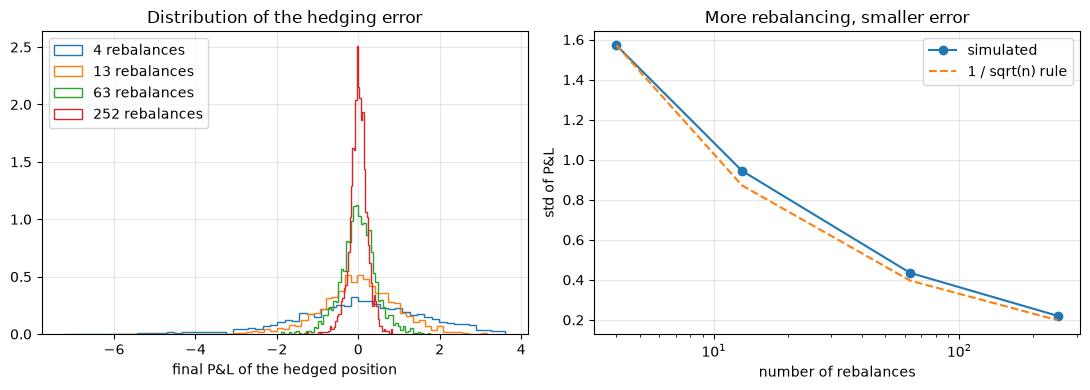

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for n, pnl in results.items():
    axes[0].hist(pnl, bins=60, histtype="step", density=True, label=f"{n} rebalances")
axes[0].set_xlabel("final P&L of the hedged position"); axes[0].set_title("Distribution of the hedging error")
axes[0].legend()

ns = np.array(list(results))
stds = np.array([results[n].std() for n in ns])
axes[1].plot(ns, stds, "o-", label="simulated")
axes[1].plot(ns, stds[0] * np.sqrt(ns[0] / ns), "--", label="1 / sqrt(n) rule")
axes[1].set_xscale("log"); axes[1].set_xlabel("number of rebalances"); axes[1].set_ylabel("std of P&L")
axes[1].set_title("More rebalancing, smaller error"); axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

- The average P&L stays close to zero: the option premium pays for the hedge.
- The error shrinks roughly like 1 / square root of the number of rebalances: hedging four times
  more often halves the error.
- In practice every rebalance costs money (bid-ask), so traders do not hedge continuously.